<a href="https://colab.research.google.com/github/192412566/mechine-learning-lab/blob/main/Harini_Mech_Learn_Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATA
   Hours  Marks
0      1     35
1      2     40
2      3     45
3      4     50
4      5     55
5      6     60
6      7     65
7      8     70
8      9     75
9     10     80

Training samples: 8
Testing samples : 2

Linear Regression model trained successfully!

Linear Regression Equation:
Marks = 5.0 × Hours + 30.0

ACTUAL VS PREDICTED
 Hours  Actual Marks  Predicted Marks
     9            75             75.0
     2            40             40.0

MODEL PERFORMANCE
Mean Absolute Error (MAE) : 0.0
Mean Squared Error (MSE)  : 0.0
Root Mean Squared Error   : 0.0
R² Score                  : 1.0

NEW SAMPLE PREDICTION
Hours Studied: 7.5
Predicted Marks: 67.5


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


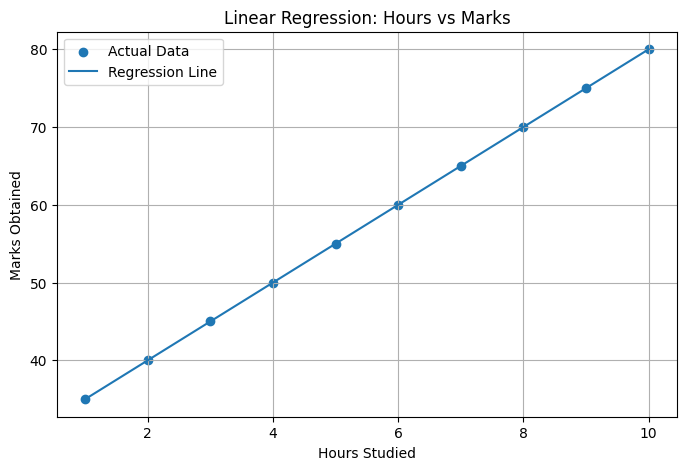

In [1]:
# ============================================================
# LINEAR REGRESSION
# Google Colab - No CSV Required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ------------------------------------------------------------
# 1. Create Dataset
# ------------------------------------------------------------

data = pd.DataFrame({
    'Hours': [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10
    ],

    'Marks': [
        35, 40, 45, 50, 55,
        60, 65, 70, 75, 80
    ]
})

print("TRAINING DATA")
print("=" * 50)
print(data)


# ------------------------------------------------------------
# 2. Separate Input and Output
# ------------------------------------------------------------

X = data[['Hours']]
y = data['Marks']


# ------------------------------------------------------------
# 3. Split Dataset
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


# ------------------------------------------------------------
# 4. Create Linear Regression Model
# ------------------------------------------------------------

model = LinearRegression()


# ------------------------------------------------------------
# 5. Train the Model
# ------------------------------------------------------------

model.fit(
    X_train,
    y_train
)

print("\nLinear Regression model trained successfully!")


# ------------------------------------------------------------
# 6. Display Equation
# ------------------------------------------------------------

slope = model.coef_[0]
intercept = model.intercept_

print("\nLinear Regression Equation:")
print(
    "Marks =",
    round(slope, 2),
    "× Hours +",
    round(intercept, 2)
)


# ------------------------------------------------------------
# 7. Predict Test Data
# ------------------------------------------------------------

y_pred = model.predict(
    X_test
)


# ------------------------------------------------------------
# 8. Display Actual vs Predicted
# ------------------------------------------------------------

result = pd.DataFrame({
    'Hours': X_test['Hours'].values,
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred
})

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

print(
    result.round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 9. Calculate Performance Metrics
# ------------------------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print("Mean Absolute Error (MAE) :", round(mae, 2))
print("Mean Squared Error (MSE)  :", round(mse, 2))
print("Root Mean Squared Error   :", round(rmse, 2))
print("R² Score                  :", round(r2, 4))


# ------------------------------------------------------------
# 10. Predict Marks for a New Student
# ------------------------------------------------------------

new_hours = np.array([
    [7.5]
])

predicted_marks = model.predict(
    new_hours
)

print("\n" + "=" * 60)
print("NEW SAMPLE PREDICTION")
print("=" * 60)

print(
    "Hours Studied:",
    new_hours[0][0]
)

print(
    "Predicted Marks:",
    round(predicted_marks[0], 2)
)


# ------------------------------------------------------------
# 11. Visualization
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

# Original data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Regression line
plt.plot(
    X,
    model.predict(X),
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Marks Obtained")

plt.title("Linear Regression: Hours vs Marks")

plt.legend()
plt.grid(True)

plt.show()